In [ ]:
import random
import matplotlib.pyplot as plt
import torch
import torch.optim as optim
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
import torchvision
import torchvision.transforms as transforms

random.seed(42)
torch.manual_seed(42)

In [78]:
#device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device = torch.device('cpu')

In [79]:
fast_mode = True
batch_size = 16
dropout = 0.1
learning_rate = 0.0001
epochs = 10 if fast_mode else 30

In [80]:
transform_train = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.3403, 0.3121, 0.3214), (0.2724, 0.2608, 0.2669))
])
transform_test = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.3403, 0.3121, 0.3214), (0.2724, 0.2608, 0.2669))
])

train_data_full = torchvision.datasets.GTSRB(root='./data', split='train', download=True, transform=transform_train)
test_data = torchvision.datasets.GTSRB(root='./data', split='test', download=True, transform=transform_test)

train_size = int(0.8 * len(train_data_full))
val_size = len(train_data_full) - train_size
train_data, val_data = random_split(train_data_full, [train_size, val_size])

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

print(f"Train samples: {len(train_data)}, Evaluation samples: {len(val_data)}, Test samples: {len(test_data)}")

Train samples: 21312, Evaluation samples: 5328, Test samples: 12630


In [81]:
class CustomTrafficSignCNN(nn.Module):
    def __init__(self):
        super(CustomTrafficSignCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Dropout(dropout)
        )
        self.classifier = nn.Sequential(
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 43)
        )
    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

In [82]:
model = CustomTrafficSignCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
print(model)


CustomTrafficSignCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Dropout(p=0.1, inplace=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=4096, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=43, bias=True)
  )
)


In [83]:
train_losses = []
val_losses = []
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    model.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)
    val_acc = 100 * correct / total
    print(f"Epoch [{epoch+1}/{epochs} | Train Loss: {epoch_train_loss}, Evaluation Loss: {epoch_val_loss} | Evaluation Accuracy: {val_acc:.2f}%]")

Epoch [1/10 | Train Loss: 2.1586941071637757, Evaluation Loss: 1.2251517169468396 | Evaluation Accuracy: 67.06%]
Epoch [2/10 | Train Loss: 0.8203868877713207, Evaluation Loss: 0.5739534887018146 | Evaluation Accuracy: 85.53%]
Epoch [3/10 | Train Loss: 0.43687736463674287, Evaluation Loss: 0.33981712254228535 | Evaluation Accuracy: 92.14%]
Epoch [4/10 | Train Loss: 0.2823305610796666, Evaluation Loss: 0.23863665118545024 | Evaluation Accuracy: 93.86%]
Epoch [5/10 | Train Loss: 0.19693594614698276, Evaluation Loss: 0.1750814721446943 | Evaluation Accuracy: 95.91%]
Epoch [6/10 | Train Loss: 0.1545874848741585, Evaluation Loss: 0.13405981117596588 | Evaluation Accuracy: 97.30%]
Epoch [7/10 | Train Loss: 0.12141175625437463, Evaluation Loss: 0.11138530816412992 | Evaluation Accuracy: 97.37%]
Epoch [8/10 | Train Loss: 0.09735855805000346, Evaluation Loss: 0.10190839113600485 | Evaluation Accuracy: 97.60%]
Epoch [9/10 | Train Loss: 0.08195849107331932, Evaluation Loss: 0.08867197985867145 | E

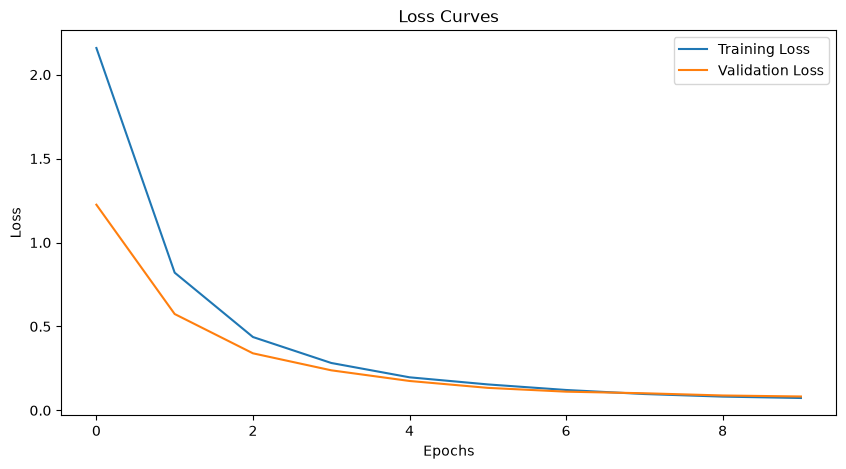

In [84]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [85]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
test_acc = 100 * correct / total
print(f"Final Test Accuracy of the model: {test_acc:.2f}%")
torch.save(model.state_dict(), 'traffic_sign_model.pth')


Final Test Accuracy of the model: 90.60%


In [5]:
pipreqs .

SyntaxError: invalid syntax (245558611.py, line 1)